In [93]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [94]:
load_dotenv()

True

In [95]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [96]:
from typing import TypedDict,Annotated

In [97]:
from langgraph.graph.message import BaseMessage,add_messages
from langchain_core.messages import RemoveMessage,AIMessage,HumanMessage

In [98]:
class chat(TypedDict):
    messages : Annotated[list[BaseMessage],add_messages]
    summary : str
    attribute : list[dict]

In [99]:
from langgraph.graph import StateGraph,START,END

In [100]:
graph = StateGraph(chat)

In [101]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

In [102]:
conn = sqlite3.connect(database='chuda.db',check_same_thread=False)
checkpoint = SqliteSaver(conn=conn)

In [103]:
from langchain_core.prompts import ChatPromptTemplate

In [104]:
prompt = ChatPromptTemplate([
    ('system',
     '''
you are working for "CHUDA _ EMPIRE" a big hotel in bengaluru,
you are a helpful chatting assistant for the users and make them feel good and assist them by
handling there query,you are going to provide the coversation so you have to answer them accordingly and make them feel good
'''),
    ('human','{convo}')
])

In [105]:
from langchain_core.output_parsers import StrOutputParser

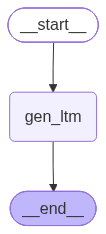

In [106]:
prompt_ltm = ChatPromptTemplate([
    ('system','''
you are a long term memory generator and you are going to provided with the details along with the conversation with the user
so you have to generate the longterm memory that we have to save with us for future and personalize use 
and remember the max attributes should be 10 not more than that and tack care that no duplicates should be there
'''),
    ('human','{convo}')
])

conn1 = sqlite3.connect(database='ltm_cuda',check_same_thread=False)
checkpoint1 = SqliteSaver(conn=conn1)
from typing import TypedDict
from pydantic import BaseModel, Field


class MemoryAttribute(BaseModel):
    key: str = Field(description="Memory attribute name")
    value: str = Field(description="Value of the memory attribute")


class ltm(BaseModel):
    attributes: list[MemoryAttribute] = Field(
        description="Unique long-term memory attributes of the user",
        max_length=10
    )

class LTMState(TypedDict):
    ltm_mem: dict
    temp: str
graph1 = StateGraph(LTMState)

ltm_chain = prompt_ltm | model.with_structured_output(ltm)

def gen_ltm(state : LTMState):
    x = state['ltm_mem']
    temp = state['temp']
    f = f'''
previous long term memory : {x}

details : {temp}
'''
    r = ltm_chain.invoke({
        'convo' : f
    })
    return {'ltm_mem' : r,'temp' : 'thread_id'}

graph1.add_node('gen_ltm',gen_ltm)
graph1.add_edge(START,'gen_ltm')
graph1.add_edge('gen_ltm',END)
wk1 = graph1.compile(checkpointer=checkpoint1)
wk1

In [107]:
parser = StrOutputParser()

In [108]:
chat_chain = prompt | model | parser

In [109]:
from langgraph.types import interrupt,Command

In [110]:
def chating(state : chat):
    summary = state['summary']
    msgs = state['messages']
    chat = f'''
    previous summary :
    {summary}

    recent chats : 
    {msgs}
'''
    r = chat_chain.invoke({
        'convo' : chat
    })
    return {'messages' : [r]}

In [111]:
prompt1 = ChatPromptTemplate([
    ('system','''
you are a chat history summarizere who have to summarize the history of the user so that we can store the history of the user
and also not losing the context and using less resources,so you have to summarize the thing in between 300 words only ,you are
going to provided by the previous summary and the recent chat history so you have to summarize both of them and generate the new important
chat history summary
'''),
    ('human','{history},{summary}')
])

In [112]:
chain_1 = prompt1 | model | parser

In [113]:
prompt2 = ChatPromptTemplate([
    ('system','''
you are a chat history summarizere who have to summarize the history of the user so that we can store the history of the user
and also not losing the context and using less resources,so you have to summarize the thing in between 300 words only ,you are
going to provided by the recent chat history so you have to summarize it and generate the new important
chat history summary
'''),
    ('human','{history}')
])

In [114]:
chain_2 = prompt2 | model | parser

In [115]:
def gen_summary(state : chat):
    s = state.get('summary', '')
    if len(state['messages']) > 10 :
        x = state['messages'][:8]
        f = f'''
summary : {s}
recent chat history : {state["messages"]}
'''
        ltm = wk1.invoke({
            'ltm_mem' : {
                'attributes' : []
            },
            'temp' : f
        })
        if state['summary']:
            s = chain_1.invoke({
                'history' : x,
                'summary' : state['summary']
            })
            return {'messages' : [RemoveMessage(id=m.id) for m in state['messages'][:8]],'summary' : s}
        else :
            s = chain_2.invoke({
                'history' : x
            })
            return {'messages' : [RemoveMessage(id=m.id) for m in state['messages'][:8]],'summary' : s}
    return {'summary' : s}

In [116]:
graph.add_node('summary',gen_summary)
graph.add_node('chat',chating)

In [117]:
graph.add_edge(START,'summary')
graph.add_edge('summary','chat')
graph.add_edge('chat',END)

In [118]:
config = {'configurable' : {
    'thread_id' : 1
}}

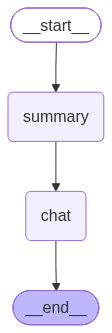

In [119]:
wk = graph.compile(checkpointer=checkpoint)
wk

In [120]:
while True:
    q = input('enter your query: ')
    if q == 'q':
        break
    print(f'YOU : {q}')
    r = wk.invoke({
        'messages' : [HumanMessage(content=q)]
    },config=config)
    print(f'AI : {r['messages'][-1].content}')

YOU : hii
AI : Hello again, Duryodhan! It's wonderful to hear from you.

Thank you for letting us know about the potential rescheduling of your meetings to **November 15th**. We appreciate you keeping us in the loop!

Does this mean you would like us to check for availability and rates for a **3-night stay** starting on **November 15th** for you and your partner? We can look into our Deluxe Double Rooms or Executive Suites for those dates.

Just let us know, and we'll be happy to assist you further!
YOU : how i can book the rooms for two extra guests
AI : Oh, wonderful! We can absolutely help you with that, Duryodhan. It's great to hear you might be bringing more guests along!

To clarify, you previously mentioned a stay for yourself and your partner. Are these two extra guests in addition to you and your partner, making it a total of **four guests**?

If so, we have a few excellent options at CHUDA _ EMPIRE to ensure everyone is comfortable:

1.  **Two Separate Rooms:** We could book 